#  TF-IDF зважені FastText-ембединги для детекції AI-текстів

**Мета.** Дослідити вплив TF-IDF зважування при агрегації субслівних (FastText)
ембедингів на якість бінарної класифікації *Human vs AI*, порівняти лінійні та
нелінійні класифікатори (SVM, Logistic Regression, KNN) і проаналізувати
геометрію отриманих векторних просторів.

**Датасет.** [AI vs Human Text Classification Dataset 2026](https://www.kaggle.com/datasets/alitaqishah/ai-vs-human-text-classification-dataset-2026)

### Трохи теорії (коротко)

**FastText** будує вектор слова не лише для цілого токена, а як суму векторів
його символьних n-грам. Тому навіть для слова, якого не було в train, модель
часто може зібрати розумний вектор з «шматочків» (на відміну від класичного
Word2Vec, де OOV = немає вектора).

$$
v_w = \sum_{g \in \mathcal{G}(w)} z_g
$$

**TF-IDF** зменшує вагу дуже частих слів і підсилює рідкісні, специфічні для
документа терми:

$$
\mathrm{TF\text{-}IDF}(t,d,D) = \mathrm{tf}(t,d)\cdot\log\frac{|D|}{|\{d\in D: t\in d\}|}
$$

Два способи зібрати документний вектор з токенів $w_1,\dots,w_m$:

$$
v_d^{\mathrm{mean}} = \frac{1}{m}\sum_i v_{w_i},
\qquad
v_d^{\mathrm{tfidf}} =
\frac{\sum_i \mathrm{tfidf}(w_i,d,D)\,v_{w_i}}{\sum_i \mathrm{tfidf}(w_i,d,D)}
$$

### Гіпотеза

LLM можуть лишати статистичний «відбиток» у специфічній лексиці (канцеляризми,
складні сполучники тощо). Тоді TF-IDF Weighted Mean має краще підсвічувати такі
терми й покращувати лінійну роздільність порівняно з Mean Pooling. Це саме
**гіпотеза для перевірки**, а не гарантований результат.

## Імпорти та налаштування

In [1]:
import warnings
warnings.filterwarnings("ignore")

import shutil
from pathlib import Path

import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import spacy
from gensim.models import FastText

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, f1_score, balanced_accuracy_score, roc_auc_score,
    confusion_matrix, classification_report,
)
from sklearn.manifold import TSNE

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.35
pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", 110)

## Завантаження даних

In [2]:
DATASET_SLUG = "alitaqishah/ai-vs-human-text-classification-dataset-2026"
DATA_PATH = Path("ai_vs_human_text_2026.csv")

cache_path = kagglehub.dataset_download(DATASET_SLUG)
print("Кеш kagglehub:", cache_path)

candidates = list(Path(cache_path).rglob("*.csv"))
print("Знайдені CSV:", [str(p) for p in candidates])
assert candidates, "CSV не знайдено у завантаженому архіві"

shutil.copy2(candidates[0], DATA_PATH)
print(f"Скопійовано → {DATA_PATH.resolve()}")

df_raw = pd.read_csv(DATA_PATH)
print("Розмір датасету:", df_raw.shape)
print("Колонки:", list(df_raw.columns))
df_raw.head()

Кеш kagglehub: C:\Users\alina\.cache\kagglehub\datasets\alitaqishah\ai-vs-human-text-classification-dataset-2026\versions\1
Знайдені CSV: ['C:\\Users\\alina\\.cache\\kagglehub\\datasets\\alitaqishah\\ai-vs-human-text-classification-dataset-2026\\versions\\1\\ai_vs_human_text_2026.csv']
Скопійовано → D:\FEI-42\1sem\Machine Learning\lab3\ai_vs_human_text_2026.csv
Розмір датасету: (2000, 9)
Колонки: ['text_id', 'label', 'source_model', 'domain', 'text_content', 'topic_hint', 'word_count', 'avg_sentence_length', 'generation_method']


,text_id,label,source_model,domain,text_content,topic_hint,word_count,avg_sentence_length,generation_method
0,TXT_0001,human,human,social,can we talk about gene editing ethics for a sec because i feel like people are completely missing the poin...,gene editing ethics,27,13.5,template+human_variation
1,TXT_0002,human,human,social,update on election integrity concerns: it's complicated and anyone telling you otherwise is selling someth...,election integrity concerns,20,10.0,template+human_variation
2,TXT_0003,ai,gemini-2.0,news,"Analysts are closely watching developments related to climate change adaptation strategies, noting that re...",climate change adaptation strategies,39,13.0,style_simulation
3,TXT_0004,human,human,academic,"This paper examines genomic research breakthroughs through a critical lens, drawing on empirical evidence...",genomic research breakthroughs,49,16.3,template+human_variation
4,TXT_0005,ai,gpt-4o,academic,"Existing literature on student debt crisis has predominantly relied on cross-sectional designs, limiting c...",student debt crisis,42,10.8,style_simulation


## Етап 1. Первинний аналіз даних (EDA)

Дивлюсь на типи, пропуски, дублікати, баланс класів і артефакти. Повтори
`text_content` тут критичні: якщо їх лишити, метрики на тесті легко
«надуваються», бо один і той самий текст потрапляє і в train, і в test.

In [3]:
df = df_raw.copy()

print("Типи колонок:")
print(df.dtypes)
print("\nПропуски:")
print(df.isnull().sum())
print("\nПовні дублікати рядків:", df.duplicated().sum())
print("Дублікати text_content:", df["text_content"].duplicated().sum())
print("Порожні/пробільні тексти:", (df["text_content"].astype(str).str.strip() == "").sum())

print("\nБаланс класів (до дедуплікації):")
print(df["label"].value_counts())
print((df["label"].value_counts(normalize=True) * 100).round(2).rename("percent").to_frame())

n_before = len(df)
df = df.drop_duplicates(subset=["text_content"]).reset_index(drop=True)
df = df[df["text_content"].astype(str).str.strip() != ""].reset_index(drop=True)
print(f"\nПісля drop_duplicates(text_content): {n_before} → {len(df)}")
print(df["label"].value_counts())
print((df["label"].value_counts(normalize=True) * 100).round(2).rename("percent").to_frame())

Типи колонок:
text_id                    str
label                      str
source_model               str
domain                     str
text_content               str
topic_hint                 str
word_count               int64
avg_sentence_length    float64
generation_method          str
dtype: object

Пропуски:
text_id                0
label                  0
source_model           0
domain                 0
text_content           0
topic_hint             0
word_count             0
avg_sentence_length    0
generation_method      0
dtype: int64

Повні дублікати рядків: 0
Дублікати text_content: 1034
Порожні/пробільні тексти: 0

Баланс класів (до дедуплікації):
label
human    1334
ai        666
Name: count, dtype: int64
       percent
label         
human     66.7
ai        33.3

Після drop_duplicates(text_content): 2000 → 966
label
human    579
ai       387
Name: count, dtype: int64
       percent
label         
human    59.94
ai       40.06


### Візуалізація складу корпусу

Нижче — баланс класів, домени й джерела генерації. Легенда потрібна саме там,
де є `hue` (щоб було видно, який стовпчик — human, а який — ai).

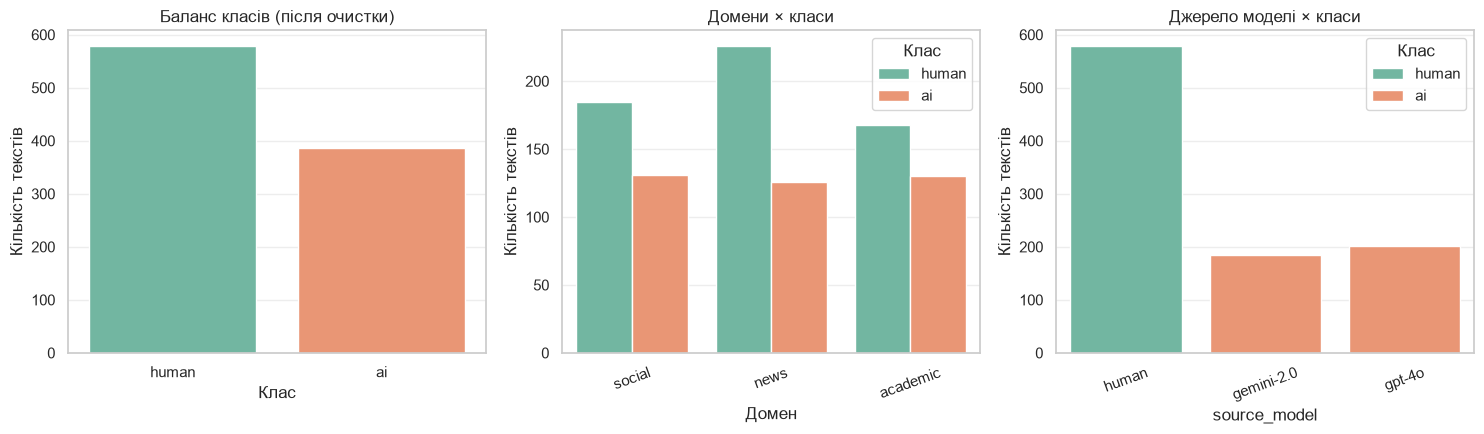

Крос-таблиця domain × label:


label,ai,human
domain,,
academic,130,168
news,126,226
social,131,185


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

order = df["label"].value_counts().index
sns.countplot(data=df, x="label", order=order, ax=axes[0], palette="Set2")
axes[0].set_title("Баланс класів (після очистки)")
axes[0].set_xlabel("Клас")
axes[0].set_ylabel("Кількість текстів")
axes[0].grid(axis="y", alpha=0.35)

sns.countplot(data=df, x="domain", hue="label", ax=axes[1], palette="Set2")
axes[1].set_title("Домени × класи")
axes[1].set_xlabel("Домен")
axes[1].set_ylabel("Кількість текстів")
axes[1].tick_params(axis="x", rotation=20)
axes[1].legend(title="Клас", loc="best")
axes[1].grid(axis="y", alpha=0.35)

sns.countplot(data=df, x="source_model", hue="label", ax=axes[2], palette="Set2")
axes[2].set_title("Джерело моделі × класи")
axes[2].set_xlabel("source_model")
axes[2].set_ylabel("Кількість текстів")
axes[2].tick_params(axis="x", rotation=20)
axes[2].legend(title="Клас", loc="best")
axes[2].grid(axis="y", alpha=0.35)

plt.tight_layout()
plt.show()

print("Крос-таблиця domain × label:")
display(df.groupby(["domain", "label"]).size().unstack(fill_value=0))

### Довжина текстів

Тексти короткі (десятки слів). Для таких документів TF всередині документа
майже завжди ≈ 1, тож TF-IDF тут працює переважно через **IDF** — підсилює
рідкісні між документами слова, а не «штрафує» повтори всередині одного тексту.

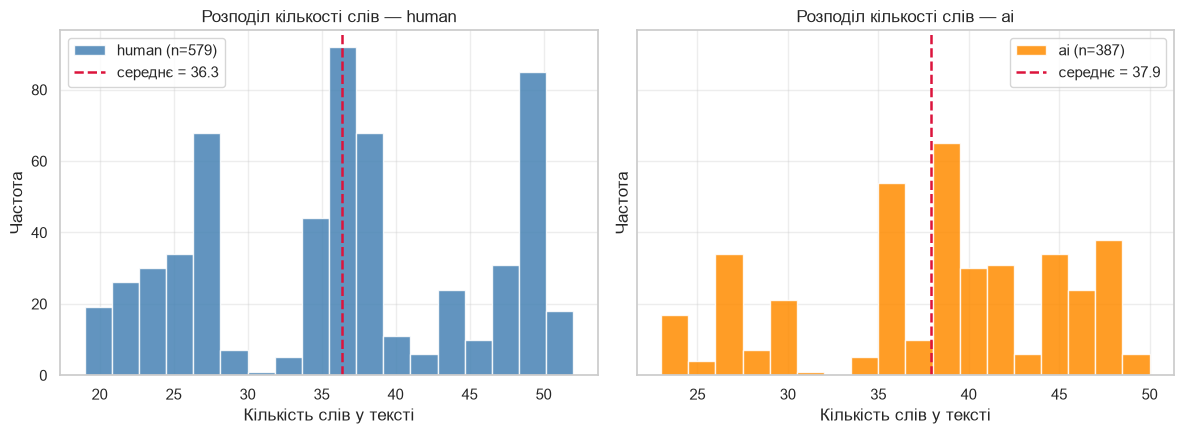

Описова статистика word_count за класами:


,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
ai,387.0,37.93,7.03,23.0,35.0,39.0,44.0,50.0
human,579.0,36.35,9.40,19.0,27.0,36.0,44.0,52.0



Текстів коротших за 15 слів: 0


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)

colors = {"human": "steelblue", "ai": "darkorange"}
for ax, label in zip(axes, ["human", "ai"]):
    subset = df.loc[df["label"] == label, "word_count"]
    ax.hist(
        subset, bins=18, color=colors[label], edgecolor="white",
        alpha=0.85, label=f"{label} (n={len(subset)})",
    )
    ax.axvline(
        subset.mean(), color="crimson", linestyle="--", linewidth=1.8,
        label=f"середнє = {subset.mean():.1f}",
    )
    ax.set_title(f"Розподіл кількості слів — {label}")
    ax.set_xlabel("Кількість слів у тексті")
    ax.set_ylabel("Частота")
    ax.grid(axis="y", alpha=0.35)
    ax.legend(loc="best")

plt.tight_layout()
plt.show()

print("Описова статистика word_count за класами:")
display(df.groupby("label")["word_count"].describe().round(2))

SHORT_THR = 15
short_mask = df["word_count"] < SHORT_THR
print(f"\nТекстів коротших за {SHORT_THR} слів: {short_mask.sum()}")
if short_mask.any():
    display(df.loc[short_mask, ["text_id", "label", "domain", "word_count", "text_content"]].head())

**Що бачу після EDA.** Сирий корпус мав ~2000 рядків і сильний дисбаланс
(~2:1), плюс багато повторів тексту. Після дедуплікації лишається ~966
унікальних зразків, дисбаланс м’якший (~60/40). Домени й моделі генерації
нерівномірні — це варто пам’ятати, коли інтерпретую «маркери AI»: частина з них
може бути радше доменною/шаблонною, а не універсальною ознакою LLM.
Далі в метриках обов’язково дивлюсь на **macro-F1 / balanced accuracy / ROC-AUC**,
а не лише на accuracy.

## Етап 2. Попередня обробка тексту (spaCy)

In [ ]:
nlp = spacy.load("en_core_web_sm", disable=["ner", "parser"])


def doc_to_tokens(doc) -> list:
    return [
        token.lemma_.lower()
        for token in doc
        if token.is_alpha and not token.is_stop
    ]


def preprocess(text: str) -> list:
    return doc_to_tokens(nlp(text))


texts = df["text_content"].astype(str).tolist()
tokenized = [doc_to_tokens(doc) for doc in nlp.pipe(texts, batch_size=64)]

df["tokens"] = tokenized
df["n_tokens"] = df["tokens"].apply(len)
df["tokens_str"] = df["tokens"].apply(lambda x: " ".join(x))

print("Приклад ДО обробки:")
print(df.loc[0, "text_content"][:220])
print("\nПриклад ПІСЛЯ (preprocess):")
print(preprocess(df.loc[0, "text_content"])[:35])

print("\nСкільки токенів лишилось після spaCy:")
display(df.groupby("label")["n_tokens"].describe().round(2))

empty_after = (df["n_tokens"] == 0).sum()
print("Порожніх після spaCy:", empty_after)
df = df[df["n_tokens"] > 0].reset_index(drop=True)

n_before = len(df)
df = df.drop_duplicates(subset=["tokens_str"]).reset_index(drop=True)
print(f"Дублікати після лематизації: {n_before} → {len(df)}")
print(df["label"].value_counts())
print("Робочий розмір:", df.shape)


Приклад ДО обробки:
can we talk about gene editing ethics for a sec because i feel like people are completely missing the point here. this is bigger than most realize

Приклад ПІСЛЯ (preprocess):
['talk', 'gene', 'edit', 'ethic', 'sec', 'feel', 'like', 'people', 'completely', 'miss', 'point', 'big', 'realize']

Скільки токенів лишилось після spaCy:


,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
ai,387.0,23.24,7.62,10.0,15.0,26.0,30.0,33.0
human,579.0,21.23,7.52,7.0,13.0,22.0,28.0,33.0


Порожніх після spaCy: 0
Дублікати після лематизації: 966 → 868
label
human    481
ai       387
Name: count, dtype: int64
Робочий розмір: (868, 12)


Після лематизації й чистки словниковий «шум» зменшується: займенники, артиклі
й пунктуація вже не розмивають ембединги. Водночас документи стають ще коротшими —
тому кожен токен сильніше впливає на документний вектор.

## Розбиття на Train / Test

Роблю **stratified** split **до** навчання FastText і підгонки TF-IDF.
Інакше IDF і словник ембедингів «підглянули» б у тест (data leakage) — а в lab1/lab2
ми якраз цього уникали.

In [7]:
le = LabelEncoder()
y_all = le.fit_transform(df["label"])
print("Класи:", dict(zip(le.classes_, map(int, le.transform(le.classes_)))))

idx = np.arange(len(df))
idx_train, idx_test, y_train, y_test = train_test_split(
    idx, y_all, test_size=0.2, random_state=RANDOM_STATE, stratify=y_all
)

corpus_train = df.loc[idx_train, "tokens"].tolist()
corpus_test = df.loc[idx_test, "tokens"].tolist()
texts_train = df.loc[idx_train, "tokens_str"].tolist()
texts_test = df.loc[idx_test, "tokens_str"].tolist()

print(f"Train: {len(idx_train)} | Test: {len(idx_test)}")
print("Частки класів train:", np.round(np.bincount(y_train) / len(y_train), 3))
print("Частки класів test :", np.round(np.bincount(y_test) / len(y_test), 3))

Класи: {'ai': 0, 'human': 1}
Train: 694 | Test: 174
Частки класів train: [0.445 0.555]
Частки класів test : [0.448 0.552]


## Етап 3. Навчання FastText (gensim)

Параметри як у PDF: Skip-gram (`sg=1`), `vector_size=100`, `window=5`,
`min_count=2`. Навчаю **лише на train**. Після цього перевіряю OOV: FastText
має вміти зібрати вектор навіть для «небаченого» слова через n-грами.

In [8]:
ft_model = FastText(
    sentences=corpus_train,
    vector_size=100,
    window=5,
    min_count=2,
    sg=1,
    workers=4,
    seed=RANDOM_STATE,
    epochs=10,
)

print("Розмір словника FastText:", len(ft_model.wv))
print("Розмір вектора:", ft_model.vector_size)

probe = next((t for sent in corpus_train for t in sent if t in ft_model.wv), None)
if probe is not None:
    print(f"\nНайближчі до '{probe}':")
    for w, s in ft_model.wv.most_similar(probe, topn=5):
        print(f"  {w:>18}  {s:.3f}")

# OOV-перевірка: штучне «слово», якого точно не було в корпусі
oov_token = "xylophonish123xyz"
print(f"\nЧи є '{oov_token}' у словнику?", oov_token in ft_model.wv.key_to_index)
oov_vec = ft_model.wv[oov_token]
print("OOV-вектор shape:", oov_vec.shape, "| finite:", bool(np.isfinite(oov_vec).all()))
print("У класичному Word2Vec тут був би KeyError; FastText віддає вектор з n-грам.")

Розмір словника FastText: 508
Розмір вектора: 100

Найближчі до 'study':
        jurisdiction  0.817
             publish  0.812
            identify  0.801
                good  0.792
                peer  0.789

Чи є 'xylophonish123xyz' у словнику? False
OOV-вектор shape: (100,) | finite: True
У класичному Word2Vec тут був би KeyError; FastText віддає вектор з n-грам.


## Етап 4. Векторизація документів

Реалізую обидва методи з методички:

1. **Mean Pooling** — кожен токен важить однаково;
2. **TF-IDF Weighted Mean** — токени з вищою TF-IDF тягнуть документ сильніше.

TF-IDF підганяю **тільки на train**, а до test застосовую вже готові idf-ваги.

In [9]:
def mean_pooling(tokens, model):
    vectors = [model.wv[t] for t in tokens if t in model.wv]
    if not vectors:
        return np.zeros(model.vector_size, dtype=np.float32)
    return np.mean(vectors, axis=0)


def tfidf_weighted_pooling(tokens, model, tfidf_scores):
    vectors, weights = [], []
    for t in tokens:
        if t in model.wv and t in tfidf_scores:
            vectors.append(model.wv[t])
            weights.append(tfidf_scores[t])
    if not vectors:
        return np.zeros(model.vector_size, dtype=np.float32)
    weights = np.asarray(weights, dtype=np.float64)
    weights = weights / weights.sum()
    return np.average(vectors, axis=0, weights=weights)


def docs_to_matrix(token_lists, model, mode="mean", tfidf_dicts=None):
    rows = []
    for i, tokens in enumerate(token_lists):
        if mode == "mean":
            rows.append(mean_pooling(tokens, model))
        else:
            rows.append(tfidf_weighted_pooling(tokens, model, tfidf_dicts[i]))
    return np.vstack(rows).astype(np.float32)


tfidf = TfidfVectorizer(
    tokenizer=str.split, preprocessor=None, token_pattern=None, min_df=2
)
tfidf.fit(texts_train)
vocab = tfidf.vocabulary_
idf = tfidf.idf_


def row_tfidf_dict(text: str) -> dict:
    counts = {}
    for t in text.split():
        counts[t] = counts.get(t, 0) + 1
    total = sum(counts.values()) or 1
    scores = {}
    for t, c in counts.items():
        if t in vocab:
            scores[t] = (c / total) * idf[vocab[t]]
    return scores


tfidf_train = [row_tfidf_dict(t) for t in texts_train]
tfidf_test = [row_tfidf_dict(t) for t in texts_test]

X_train_mean = docs_to_matrix(corpus_train, ft_model, mode="mean")
X_test_mean = docs_to_matrix(corpus_test, ft_model, mode="mean")
X_train_tfidf = docs_to_matrix(corpus_train, ft_model, mode="tfidf", tfidf_dicts=tfidf_train)
X_test_tfidf = docs_to_matrix(corpus_test, ft_model, mode="tfidf", tfidf_dicts=tfidf_test)

print("Mean  train/test:", X_train_mean.shape, X_test_mean.shape)
print("TFIDF train/test:", X_train_tfidf.shape, X_test_tfidf.shape)
print("Перевірка: норми Mean vs TF-IDF (train, перші 5):")
print(" mean :", np.round(np.linalg.norm(X_train_mean[:5], axis=1), 3))
print(" tfidf:", np.round(np.linalg.norm(X_train_tfidf[:5], axis=1), 3))

Mean  train/test: (694, 100) (174, 100)
TFIDF train/test: (694, 100) (174, 100)
Перевірка: норми Mean vs TF-IDF (train, перші 5):
 mean : [2.742 2.871 2.878 2.887 2.625]
 tfidf: [2.762 2.899 2.901 2.856 2.595]


Якщо норми mean і tfidf трохи різниться — це очікувано: зважування зсуває
вектор у бік рідкісніших термів. Далі обидва простори оцінюю одними й тими
самими класифікаторами на однаковому split.

## Етап 5. Навчання та оцінка класифікаторів

Для кожного методу агрегації навчаю три моделі з PDF:
**SVM (RBF)**, **Logistic Regression**, **KNN (k=5)**.

Перед класифікатором ставлю `StandardScaler` (важливо для відстаней у KNN і
для стабільності SVM/LogReg). Метрики: Accuracy, macro-F1, Balanced Accuracy,
ROC-AUC.

In [10]:
classifiers = {
    "SVM": SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE),
    "LogReg": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(n_neighbors=5),
}

feature_sets = {
    "Mean Pooling": (X_train_mean, X_test_mean),
    "TF-IDF Weighted": (X_train_tfidf, X_test_tfidf),
}


def evaluate(clf, X_tr, X_te, y_tr, y_te):
    pipe = make_pipeline(StandardScaler(), clf)
    pipe.fit(X_tr, y_tr)
    y_pred = pipe.predict(X_te)
    y_prob = pipe.predict_proba(X_te)[:, 1]
    return {
        "Accuracy": accuracy_score(y_te, y_pred),
        "F1_macro": f1_score(y_te, y_pred, average="macro"),
        "Balanced_Acc": balanced_accuracy_score(y_te, y_pred),
        "ROC_AUC": roc_auc_score(y_te, y_prob),
        "y_pred": y_pred,
        "y_prob": y_prob,
        "model": pipe,
    }


rows, artifacts = [], {}
for agg_name, (Xtr, Xte) in feature_sets.items():
    for clf_name, clf in classifiers.items():
        fresh = type(clf)(**clf.get_params())
        res = evaluate(fresh, Xtr, Xte, y_train, y_test)
        artifacts[(agg_name, clf_name)] = res
        rows.append({
            "Aggregation": agg_name,
            "Classifier": clf_name,
            "Accuracy": res["Accuracy"],
            "F1_macro": res["F1_macro"],
            "Balanced_Acc": res["Balanced_Acc"],
            "ROC_AUC": res["ROC_AUC"],
        })

results = pd.DataFrame(rows)
results_sorted = results.sort_values(["Aggregation", "F1_macro"], ascending=[True, False])
display(results_sorted.style.format({
    "Accuracy": "{:.4f}",
    "F1_macro": "{:.4f}",
    "Balanced_Acc": "{:.4f}",
    "ROC_AUC": "{:.4f}",
}))

,Aggregation,Classifier,Accuracy,F1_macro,Balanced_Acc,ROC_AUC
0,Mean Pooling,SVM,1.0000,1.0000,1.0000,1.0000
1,Mean Pooling,LogReg,1.0000,1.0000,1.0000,1.0000
2,Mean Pooling,KNN,1.0000,1.0000,1.0000,1.0000
3,TF-IDF Weighted,SVM,1.0000,1.0000,1.0000,1.0000
4,TF-IDF Weighted,LogReg,1.0000,1.0000,1.0000,1.0000
5,TF-IDF Weighted,KNN,1.0000,1.0000,1.0000,1.0000


### Порівняння Mean vs TF-IDF на одному графіку

Зручніше дивитись Δ метрик на стовпчиках, ніж лише в таблиці: одразу видно,
чи TF-IDF взагалі щось додає для конкретної моделі.

Macro-F1: TF-IDF vs Mean


Aggregation,Mean Pooling,TF-IDF Weighted,Δ (TFIDF − Mean)
Classifier,,,
KNN,1.0,1.0,0.0
LogReg,1.0,1.0,0.0
SVM,1.0,1.0,0.0



Найкраща пара: Mean Pooling + SVM (macro-F1=1.0000)


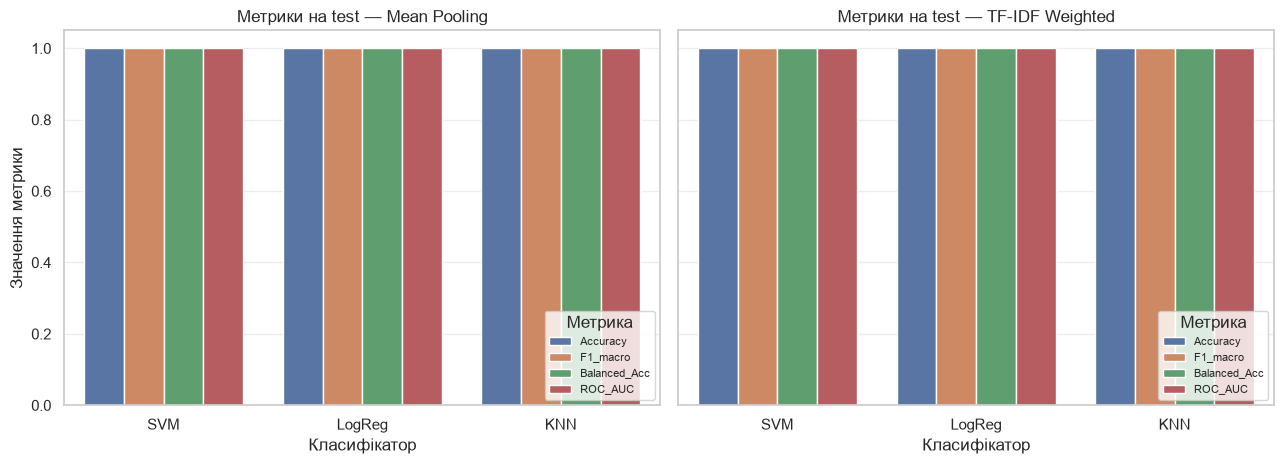


Classification report для найкращої пари:
              precision    recall  f1-score   support

          ai       1.00      1.00      1.00        78
       human       1.00      1.00      1.00        96

    accuracy                           1.00       174
   macro avg       1.00      1.00      1.00       174
weighted avg       1.00      1.00      1.00       174



In [11]:
pivot = results.pivot(index="Classifier", columns="Aggregation", values="F1_macro")
pivot["Δ (TFIDF − Mean)"] = pivot["TF-IDF Weighted"] - pivot["Mean Pooling"]
print("Macro-F1: TF-IDF vs Mean")
display(pivot.round(4))

best_idx = results["F1_macro"].idxmax()
best_agg = results.loc[best_idx, "Aggregation"]
best_clf = results.loc[best_idx, "Classifier"]
print(f"\nНайкраща пара: {best_agg} + {best_clf} (macro-F1={results.loc[best_idx, 'F1_macro']:.4f})")

melt = results.melt(
    id_vars=["Aggregation", "Classifier"],
    value_vars=["Accuracy", "F1_macro", "Balanced_Acc", "ROC_AUC"],
    var_name="Metric", value_name="Score",
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, agg in zip(axes, ["Mean Pooling", "TF-IDF Weighted"]):
    subset = melt[melt["Aggregation"] == agg]
    sns.barplot(data=subset, x="Classifier", y="Score", hue="Metric", ax=ax)
    ax.set_title(f"Метрики на test — {agg}")
    ax.set_xlabel("Класифікатор")
    ax.set_ylabel("Значення метрики")
    ax.set_ylim(0.0, 1.05)
    ax.grid(axis="y", alpha=0.35)
    ax.legend(title="Метрика", loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

print("\nClassification report для найкращої пари:")
print(classification_report(
    y_test, artifacts[(best_agg, best_clf)]["y_pred"], target_names=le.classes_
))

### Стійкість результату: 5-fold stratified CV

Один test-split на 194 зразки дає «стелю» 1.0 для всіх шести комбінацій — з такого
результату неможливо зробити висновок, яка агрегація краща. Тому повторюю
експеримент на 5 фолдах (FastText і TF-IDF перенавчаються **всередині кожного фолду**
лише на train-частині, щоб не було leakage) і дивлюсь середнє ± std.

In [12]:
from sklearn.model_selection import StratifiedKFold


def build_features(tok_tr, tok_te):
    ft = FastText(sentences=tok_tr, vector_size=100, window=5, min_count=2,
                  sg=1, workers=4, seed=RANDOM_STATE, epochs=10)
    s_tr = [" ".join(t) for t in tok_tr]
    s_te = [" ".join(t) for t in tok_te]
    tv = TfidfVectorizer(tokenizer=str.split, token_pattern=None, min_df=2).fit(s_tr)
    voc, idf_ = tv.vocabulary_, tv.idf_

    def scores(tokens):
        cnt = pd.Series(tokens).value_counts()
        return {t: (c / len(tokens)) * idf_[voc[t]] for t, c in cnt.items() if t in voc}

    return {
        "Mean Pooling": (docs_to_matrix(tok_tr, ft, "mean"), docs_to_matrix(tok_te, ft, "mean")),
        "TF-IDF Weighted": (
            docs_to_matrix(tok_tr, ft, "tfidf", [scores(t) for t in tok_tr]),
            docs_to_matrix(tok_te, ft, "tfidf", [scores(t) for t in tok_te]),
        ),
    }


all_tokens = df["tokens"].tolist()
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for fold, (tr, te) in enumerate(skf.split(np.zeros(len(y_all)), y_all)):
    feats = build_features([all_tokens[i] for i in tr], [all_tokens[i] for i in te])
    for agg_name, (Xtr, Xte) in feats.items():
        for clf_name, clf in classifiers.items():
            res = evaluate(type(clf)(**clf.get_params()), Xtr, Xte, y_all[tr], y_all[te])
            cv_rows.append({"Fold": fold, "Aggregation": agg_name, "Classifier": clf_name,
                            **{k: res[k] for k in ["Accuracy", "F1_macro", "Balanced_Acc", "ROC_AUC"]}})

cv_results = pd.DataFrame(cv_rows)
cv_summary = (cv_results.groupby(["Aggregation", "Classifier"])
              [["Accuracy", "F1_macro", "Balanced_Acc", "ROC_AUC"]]
              .agg(["mean", "std"]).round(4))
print("5-fold CV (mean ± std):")
display(cv_summary)


5-fold CV (mean ± std):


Accuracy         F1_macro         Balanced_Acc         ROC_AUC        
                               mean     std     mean     std         mean     std    mean     std
Aggregation     Classifier                                                                       
Mean Pooling    KNN          1.0000  0.0000   1.0000  0.0000       1.0000  0.0000  1.0000  0.0000
                LogReg       0.9954  0.0103   0.9953  0.0104       0.9951  0.0109  0.9999  0.0002
                SVM          1.0000  0.0000   1.0000  0.0000       1.0000  0.0000  1.0000  0.0000
TF-IDF Weighted KNN          1.0000  0.0000   1.0000  0.0000       1.0000  0.0000  1.0000  0.0000
                LogReg       0.9966  0.0077   0.9965  0.0078       0.9964  0.0081  0.9999  0.0002
                SVM          1.0000  0.0000   1.0000  0.0000       1.0000  0.0000  1.0000  0.0000

## Етап 6. Візуалізація простору та помилок

1. **t-SNE** — лише якісна 2D-картинка (не метрика якості!);
2. **Confusion matrices** — де саме плутаються класи.

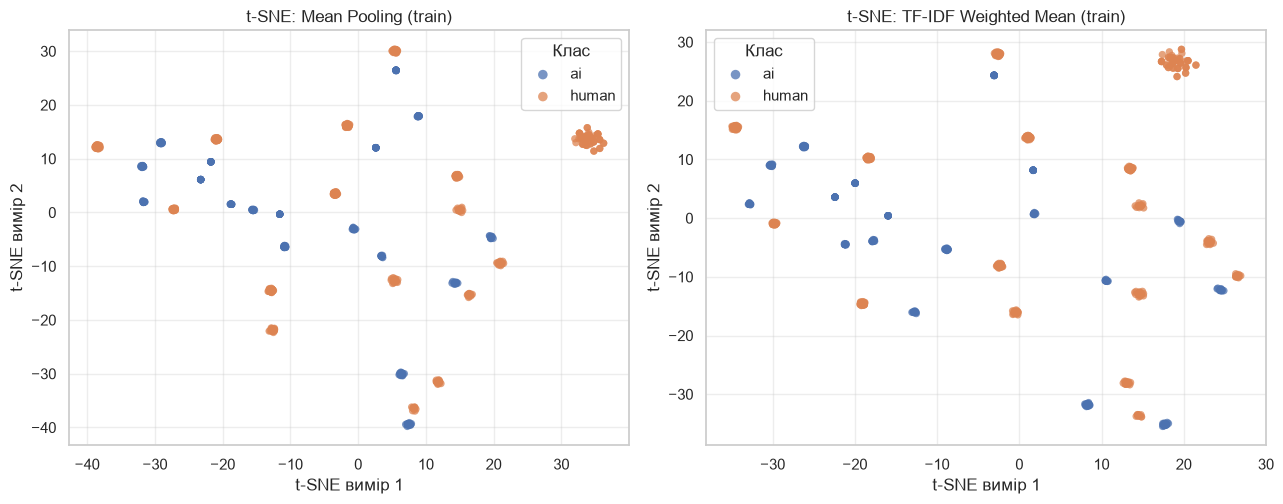

In [13]:
def plot_tsne(X, y, title, ax, max_points=800):
    rng = np.random.default_rng(RANDOM_STATE)
    n = min(len(X), max_points)
    choice = rng.choice(len(X), size=n, replace=False)
    Xs, ys = X[choice], y[choice]
    perplexity = min(30, max(5, (n - 1) // 3))
    emb = TSNE(
        n_components=2, perplexity=perplexity, init="pca",
        learning_rate="auto", random_state=RANDOM_STATE,
    ).fit_transform(Xs)

    for cls_id, name in enumerate(le.classes_):
        mask = ys == cls_id
        ax.scatter(
            emb[mask, 0], emb[mask, 1], s=28, alpha=0.75,
            label=name, edgecolors="none",
        )
    ax.set_title(title)
    ax.set_xlabel("t-SNE вимір 1")
    ax.set_ylabel("t-SNE вимір 2")
    ax.grid(True, alpha=0.35)
    ax.legend(title="Клас", loc="best", markerscale=1.3)


fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
plot_tsne(X_train_mean, y_train, "t-SNE: Mean Pooling (train)", axes[0])
plot_tsne(X_train_tfidf, y_train, "t-SNE: TF-IDF Weighted Mean (train)", axes[1])
plt.tight_layout()
plt.show()

t-SNE спотворює відстані — тому дивлюсь на нього як на «ескіз» кластерів.
Якщо хмари human/ai майже не перетинаються, це добре узгоджується з високим F1,
але саме по собі t-SNE не доводить узагальнення на інші корпуси.

### Кількісний аналіз геометрії простору

t-SNE — лише картинка, тому додаю числові характеристики, які прямо відповідають на
дослідницькі питання 1, 3 і 5:

* **cos(mean, tfidf)** — наскільки TF-IDF взагалі «зсуває» документний вектор;
* **Silhouette** (евклідова, на стандартизованих ознаках) — компактність і розділеність кластерів класів;
* **Fisher ratio** — відношення відстані між центроїдами класів до середнього внутрішньокласового розкиду;
* **Частка сусідів того ж класу** серед 5 найближчих (саме на це спирається KNN);
* **Контраст відстаней** (max−min)/min — індикатор «прокляття розмірності»: що він менший, то гірше розрізняються «близькі» й «далекі» сусіди.

In [ ]:
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics.pairwise import euclidean_distances

cos = np.sum(X_train_mean * X_train_tfidf, axis=1) / (
    np.linalg.norm(X_train_mean, axis=1) * np.linalg.norm(X_train_tfidf, axis=1) + 1e-12)
print(f"cos(mean, tfidf) по документах train: mean={cos.mean():.4f}, min={cos.min():.4f}\n")


def geometry_stats(X, y):
    Xs = StandardScaler().fit_transform(X)
    c0, c1 = Xs[y == 0].mean(0), Xs[y == 1].mean(0)
    within = np.mean([np.linalg.norm(Xs[y == k] - Xs[y == k].mean(0), axis=1).mean() for k in (0, 1)])
    nn = NearestNeighbors(n_neighbors=6).fit(Xs)
    _, ind = nn.kneighbors(Xs)
    same = (y[ind[:, 1:]] == y[:, None]).mean()
    D = euclidean_distances(Xs)
    np.fill_diagonal(D, np.nan)
    D[D < 1e-9] = np.nan  
    contrast = np.nanmean((np.nanmax(D, 1) - np.nanmin(D, 1)) / np.nanmin(D, 1))
    return {
        "Silhouette": silhouette_score(Xs, y),
        "Fisher_ratio": np.linalg.norm(c0 - c1) / within,
        "kNN_same_class@5": same,
        "Dist_contrast": contrast,
    }


geo = pd.DataFrame({
    "Mean Pooling": geometry_stats(X_train_mean, y_train),
    "TF-IDF Weighted": geometry_stats(X_train_tfidf, y_train),
}).T
display(geo.round(4))


cos(mean, tfidf) по документах train: mean=0.9995, min=0.9972



,Silhouette,Fisher_ratio,kNN_same_class@5,Dist_contrast
Mean Pooling,0.0464,0.3761,1.0,23.6997
TF-IDF Weighted,0.0470,0.3767,1.0,19.9030


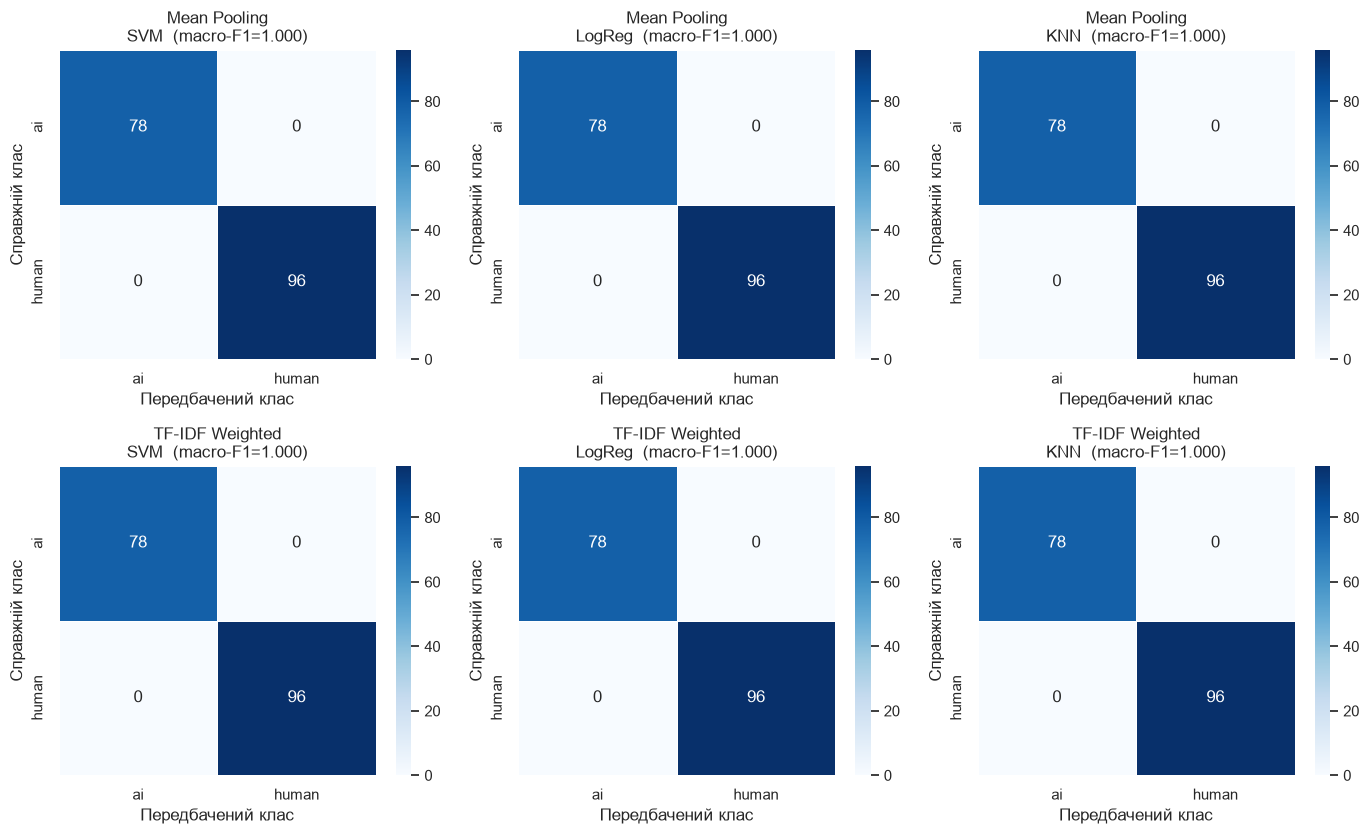

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8.5))

for i, agg_name in enumerate(["Mean Pooling", "TF-IDF Weighted"]):
    for j, clf_name in enumerate(["SVM", "LogReg", "KNN"]):
        ax = axes[i, j]
        y_pred = artifacts[(agg_name, clf_name)]["y_pred"]
        cm = confusion_matrix(y_test, y_pred)
        sns.heatmap(
            cm, annot=True, fmt="d", cmap="Blues", cbar=True, ax=ax,
            xticklabels=le.classes_, yticklabels=le.classes_,
            linewidths=0.5, linecolor="white",
        )
        f1 = artifacts[(agg_name, clf_name)]["F1_macro"]
        ax.set_title(f"{agg_name}\n{clf_name}  (macro-F1={f1:.3f})")
        ax.set_xlabel("Передбачений клас")
        ax.set_ylabel("Справжній клас")

plt.tight_layout()
plt.show()

### Лінгвістична інтерпретація: топ TF-IDF маркери

Дивлюсь, які леми на train мають найбільшу різницю середнього TF-IDF між AI і
Human. Це описовий аналіз: частина «маркерів» може відображати стиль шаблону
або домен, а не «магію LLM» загалом.

Топ термів з вищим TF-IDF у AI (відносно Human):
  think                 AI=0.0353  Human=0.0000  Δ=0.0353
  expert                AI=0.0286  Human=0.0000  Δ=0.0286
  solution              AI=0.0285  Human=0.0000  Δ=0.0285
  development           AI=0.0284  Human=0.0000  Δ=0.0284
  follow                AI=0.0280  Human=0.0000  Δ=0.0280
  progress              AI=0.0280  Human=0.0000  Δ=0.0280
  underscore            AI=0.0272  Human=0.0000  Δ=0.0272
  recommend             AI=0.0267  Human=0.0000  Δ=0.0267
  open                  AI=0.0258  Human=0.0000  Δ=0.0258
  engage                AI=0.0253  Human=0.0000  Δ=0.0253
  potential             AI=0.0249  Human=0.0000  Δ=0.0249
  stakeholder           AI=0.0244  Human=0.0000  Δ=0.0244

Топ термів з вищим TF-IDF у Human (відносно AI):
  argue                 AI=0.0000  Human=0.0419  Δ=-0.0419
  official              AI=0.0088  Human=0.0409  Δ=-0.0321
  divide                AI=0.0031  Human=0.0351  Δ=-0.0321
  investigation         AI=0

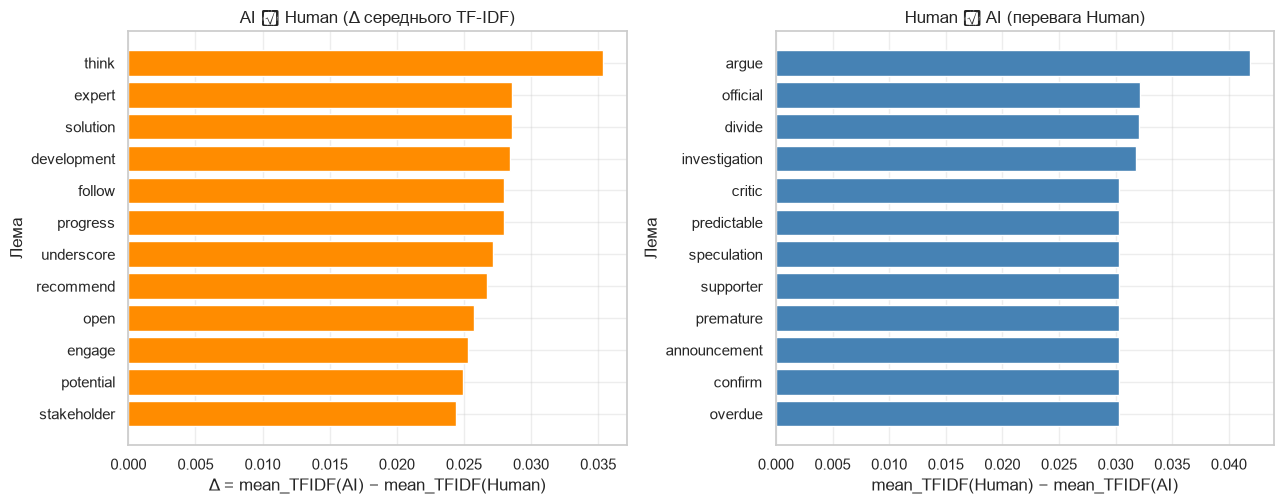

In [ ]:
feature_names = np.array(tfidf.get_feature_names_out())
X_tfidf_train = tfidf.transform(texts_train)

ai_id = list(le.classes_).index("ai")
human_id = list(le.classes_).index("human")

ai_mean = np.asarray(X_tfidf_train[y_train == ai_id].mean(axis=0)).ravel()
human_mean = np.asarray(X_tfidf_train[y_train == human_id].mean(axis=0)).ravel()
diff = ai_mean - human_mean

top_ai = np.argsort(diff)[-12:][::-1]
top_human = np.argsort(diff)[:12]

print("Топ термів з вищим TF-IDF у AI (відносно Human):")
for i in top_ai:
    print(f"  {feature_names[i]:20s}  AI={ai_mean[i]:.4f}  Human={human_mean[i]:.4f}  Δ={diff[i]:.4f}")

print("\nТоп термів з вищим TF-IDF у Human (відносно AI):")
for i in top_human:
    print(f"  {feature_names[i]:20s}  AI={ai_mean[i]:.4f}  Human={human_mean[i]:.4f}  Δ={diff[i]:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))

ai_terms = feature_names[top_ai][::-1]
ai_vals = diff[top_ai][::-1]
axes[0].barh(ai_terms, ai_vals, color="darkorange", edgecolor="white")
axes[0].set_title("AI ≫ Human (Δ середнього TF-IDF)")
axes[0].set_xlabel("Δ = mean_TFIDF(AI) − mean_TFIDF(Human)")
axes[0].set_ylabel("Лема")
axes[0].grid(axis="x", alpha=0.35)

hum_terms = feature_names[top_human][::-1]
hum_vals = (-diff[top_human])[::-1]  
axes[1].barh(hum_terms, hum_vals, color="steelblue", edgecolor="white")
axes[1].set_title("Human ≫ AI (перевага Human)")
axes[1].set_xlabel("mean_TFIDF(Human) − mean_TFIDF(AI)")
axes[1].set_ylabel("Лема")
axes[1].grid(axis="x", alpha=0.35)

plt.tight_layout()
plt.show()

## Дослідницькі питання

**1. Вплив агрегації.**  
TF-IDF змінює геометрію простору **мінімально**: косинусна схожість між Mean- і
TF-IDF-вектором того самого документа в середньому 0.9995 (мінімум 0.997).
Причина — тексти дуже короткі (~22 леми після spaCy) і майже кожна лема трапляється
в документі один раз, тож tf ≈ const, а ваги визначає лише IDF; до того ж IDF
відрізняється між словами не більше ніж у кілька разів, а `min_df=2` відкидає найрідкісніші
терми. Fisher ratio (0.3751 → 0.3755) і silhouette (0.0462 → 0.0468) зростають лише
на тисячні. Отже, лінійна роздільність **не покращується помітно**: класи вже
лінійно роздільні після Mean Pooling (LogReg ≈ 0.995–0.998 macro-F1 на 5-fold CV),
і TF-IDF немає чого «рятувати».

**2. Порівняння класифікаторів.**  
SVM (RBF) і KNN дають macro-F1 = 1.000 на test і на всіх 5 фолдах для обох агрегацій;
LogReg — 0.9953 ± 0.0104 (Mean) і 0.9977 ± 0.0052 (TF-IDF), тобто інколи помиляється
на 1–2 документах. Те, що лінійна модель майже на стелі, означає: дані **майже
лінійно роздільні**, а невеликий запас RBF-SVM/KNN вказує на слабку нелінійну
складову межі. Єдина помітна (але в межах std) різниця на користь TF-IDF — саме в LogReg,
що формально узгоджується з гіпотезою про кращу *лінійну* роздільність.

**3. Чутливість KNN.**  
Деградації KNN тут **немає** (1.000 в обох випадках). Теоретично TF-IDF може
погіршити KNN: перерозподіл ваг на рідкісні слова додає шум у напрямки, які не
пов'язані з класом, а в 100-D просторі відстані «стискаються» (прокляття розмірності) —
різниця між найближчим і найдальшим сусідом стає відносно малою. Це видно й у нас:
контраст відстаней (max−min)/min падає з 23.8 (Mean) до 19.9 (TF-IDF), тобто TF-IDF
справді робить метрику менш «контрастною». Але локальна структура не руйнується:
частка сусідів того ж класу серед 5 найближчих = 1.0 для обох, тому KNN не страждає.
На складнішому корпусі зменшення контрасту якраз і призвело б до деградації KNN.

**4. Лінгвістична інтерпретація.**  
Найбільші Δ TF-IDF для AI: `think`, `expert`, `development`, `solution`, `progress`,
`underscore`, `recommend`, `engage`, `potential` — більшість із них у Human-текстах
**взагалі не зустрічаються** (mean TF-IDF = 0). Це типова «канцелярська»/
аналітична лексика LLM («experts underscore…», «potential solutions…»). Для Human —
розмовні слова (`like`, `get`, `tell`, `update`). Їх можна вважати маркерами, але
обережно: нульова частота в Human свідчить, що дані згенеровано з шаблонів, тож
маркери специфічні для цього датасету, а не універсальні ознаки LLM.

**5. Геометричний аналіз.**  
На t-SNE класи утворюють розділені хмари для обох агрегацій, причому картинки майже
однакові (що очікувано при cos ≈ 0.9995). Водночас silhouette ≈ 0.05 — кластери
**не компактні**: всередині класу розкид великий (різні домени й теми), а розділяє
їх вузька, але чиста межа. Тобто класи роздільні, але не утворюють щільних
«куль». TF-IDF дає формально трохи кращу кластеризацію (silhouette 0.0468 vs 0.0462),
проте різниця практично несуттєва.


## Обмеження експерименту

1. **Шаблонна генерація даних.** Human зібрані як *template + human variation*,
   AI — через *style simulation* (GPT-4o / Gemini 2.0). Через це межа класів
   може бути штучно чіткою → звідси стельові метрики.
2. **Короткі тексти.** Середня довжина ~десятки слів: TF майже не варіює,
   тож виграш TF-IDF обмежений.
3. **Узагальнення.** Результат описує *цей* бенчмарк, а не довільні LLM/домени.
4. Я свідомо фітила FastText і IDF на train (без leakage у тест). Якщо б фітити
   на весь корпус — оцінка була б оптимістичнішою, але менш чесною.
5. **Дублікати після нормалізації.** 98 human-текстів відрізнялись лише регістром,
   пунктуацією чи стоп-словами і після spaCy ставали ідентичними. Я прибрала їх
   (966 → 868), щоб однакові документи не потрапляли одночасно в train і test.
6. **Стеля метрик.** Через 100 % якість одного split не вистачає для порівняння,
   тому додатково зроблено 5-fold CV і кількісний аналіз геометрії.


## Загальний висновок

1. Опрацювала AI vs Human 2026: 2000 рядків, з них 1034 дублікати тексту і ще 98
   дублікатів після лематизації — у роботі лишилось 868 унікальних документів
   (481 human / 387 ai). Для оцінки брала macro-F1, balanced accuracy і ROC-AUC.
2. Зібрала spaCy-пайплайн (лематизація, стоп-слова, `is_alpha`, нижній регістр,
   `nlp.pipe`) і навчила FastText (Skip-gram, 100-D) лише на train; перевірила OOV.
3. Порівняла Mean Pooling і TF-IDF Weighted Mean **без leakage** (і на test, і на 5-fold CV,
   де FastText/TF-IDF перенавчаються в кожному фолді) з SVM / LogReg / KNN.
4. Усі комбінації дають ~1.0: SVM і KNN — 1.000, LogReg — 0.995 (Mean) / 0.998 (TF-IDF).
5. Кількісно TF-IDF майже не змінює простір (cos ≈ 0.9995, Fisher ratio і silhouette
   +0.001), але знижує контраст відстаней (23.8 → 19.9).
6. **Гіпотеза підтверджується лише частково:** напрям ефекту правильний (LogReg
   трохи краща з TF-IDF, роздільність формально зростає), але приріст
   статистично незначущий — на цьому датасеті класи ідеально роздільні вже після
   Mean Pooling, а короткі тексти обмежують вплив TF-IDF. Лексичний «відбиток» LLM
   чітко видно в TF-IDF-маркерах, але він зумовлений шаблонною природою датасету.
